# EduGuard AI: Exploratory Data Analysis, Validation & Model Reliability
### Academic Intelligence & Early Warning Platform
**Tagline:** *Detect Early. Understand Deeply. Support Intelligently.*

--- 
## 1. Executive Summary & School Domain Problem Framing
EduGuard AI is an **advisory early-warning ML system** built to help school teachers and academic coordinators identify students who may score below **40/100** in their next assessment.

### Governance & Engineering Rules
1. **Strictly Pre-Assessment Inputs:** Features use only information available prior to the upcoming assessment.
2. **Authoritative Derived-Feature Parity:** `previous_score_avg` is consistently defined everywhere as the rolling two-assessment mean (`mean(previous_score, previous_score_2)`, falling back to `previous_score` when Period-0 prior score is absent), eliminating training-serving skew.
3. **Strict Anti-Leakage:** `next_assessment_score` is excluded from model feature matrices and zero demographic/sensitive attributes are stored or modeled.
4. **Advisory Mandate:** Predictions and SHAP attributions capture statistical associations to assist caring teacher check-ins, never automated sanctions, grading, or causal proof.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    EVALUATION_METRICS_PATH,
    FEATURE_COLUMNS,
    ID_COLUMN,
    METADATA_PATH,
    RAW_DATA_PATH,
    TARGET_COLUMN,
)
from src.data_validation import StudentDataValidator
from src.leakage_audit import LeakageAuditor

sns.set_theme(style="whitegrid")
print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {RAW_DATA_PATH}")

Project root: C:\Users\Admin\Downloads\ALGIONS AI LABS\EduGuard-AI
Dataset path: C:\Users\Admin\Downloads\ALGIONS AI LABS\EduGuard-AI\data\raw\student_performance.csv


## 2. Dataset Ingestion, Derived-Feature Consistency & Anti-Leakage Audits
We inspect the synthetic school cohort (`student_performance.csv`: 2,500 simulated students, 4 snapshots per student = 10,000 rows) and verify schema integrity, derived-feature parity, and zero target leakage.

In [2]:
df = pd.read_csv(RAW_DATA_PATH)
print(f"Dataset Shape: {df.shape}")
print(f"Unique Students: {df[ID_COLUMN].nunique()}")
display(df.head())

validator = StudentDataValidator()
val_report = validator.run_all_validations(df)
print(f"Data Validation Overall Status: {val_report['overall_status']}")

derived_check = validator.validate_derived_feature_consistency(df)
print("Derived Feature Consistency Report:", derived_check)

auditor = LeakageAuditor()
leak_report = auditor.run_full_audit(df)
print("Anti-Leakage Audit Statuses:", {k: v["status"] for k, v in leak_report.items()})

Dataset Shape: (10000, 11)
Unique Students: 2500


,student_id,assessment_period,attendance_pct,assignment_completion_pct,late_assignment_count,previous_score,previous_score_2,previous_score_avg,score_trend,next_assessment_score,at_risk
0,STU_00001,1,52.62,48.70,0,89.96,61.19,75.57,28.77,55.93,0
1,STU_00001,2,61.22,48.78,0,55.93,89.96,72.94,-34.03,66.38,0
2,STU_00001,3,63.84,54.89,0,66.38,55.93,61.16,10.45,56.59,0
3,STU_00001,4,54.71,51.08,4,56.59,66.38,61.48,-9.79,57.25,0
4,STU_00002,1,58.41,67.01,1,53.08,58.65,55.86,-5.57,53.16,0


2026-11-10 19:29:42,987 - EduGuard.DataValidation - INFO - Running validation on dataset with shape: (10000, 11)


2026-11-10 19:29:43,124 - EduGuard.DataValidation - INFO - All data validation checks passed successfully.


Data Validation Overall Status: PASS


2026-11-10 19:29:43,211 - EduGuard.LeakageAudit - INFO - Executing comprehensive Anti-Leakage & Governance Audit...


2026-11-10 19:29:43,226 - EduGuard.LeakageAudit - INFO - Anti-leakage audit passed: zero leakage detected across all checks.


Derived Feature Consistency Report: {'status': 'PASS', 'avg_mismatches': 0, 'trend_mismatches': 0, 'tolerance': 0.01}
Anti-Leakage Audit Statuses: {'feature_isolation': 'PASS', 'forbidden_attributes': 'PASS', 'target_correlations': 'PASS'}


## 3. Target Class Distribution
The binary early-warning label is `at_risk = 1` when `next_assessment_score < 40.0`, else `0`.

,Count,Percentage (%)
at_risk,,
0,8046,80.46
1,1954,19.54


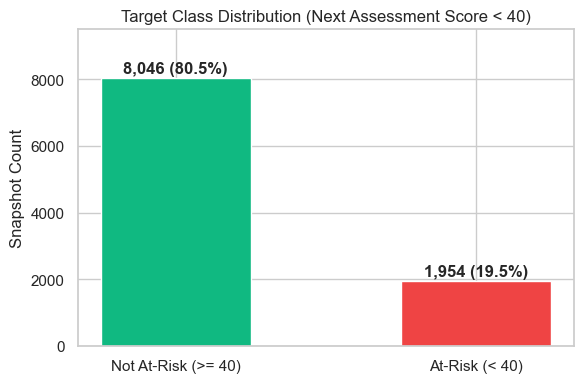

In [3]:
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
target_pct = df[TARGET_COLUMN].value_counts(normalize=True).sort_index() * 100

summary_df = pd.DataFrame({"Count": target_counts, "Percentage (%)": target_pct.round(2)})
display(summary_df)

plt.figure(figsize=(6, 4))
plt.bar(["Not At-Risk (>= 40)", "At-Risk (< 40)"], target_counts.values, color=["#10B981", "#EF4444"], width=0.5)
plt.title("Target Class Distribution (Next Assessment Score < 40)")
plt.ylabel("Snapshot Count")
for i, v in enumerate(target_counts.values):
    plt.text(i, v + 150, f"{v:,} ({target_pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")
plt.ylim(0, len(df) * 0.95)
plt.tight_layout()
plt.show()

## 4. Classroom Engagement & Academic Indicator Distributions
We inspect how classroom attendance, assignment completion, and late submissions correlate with subsequent at-risk outcomes.

2026-11-10 19:29:44,022 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-10 19:29:44,041 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


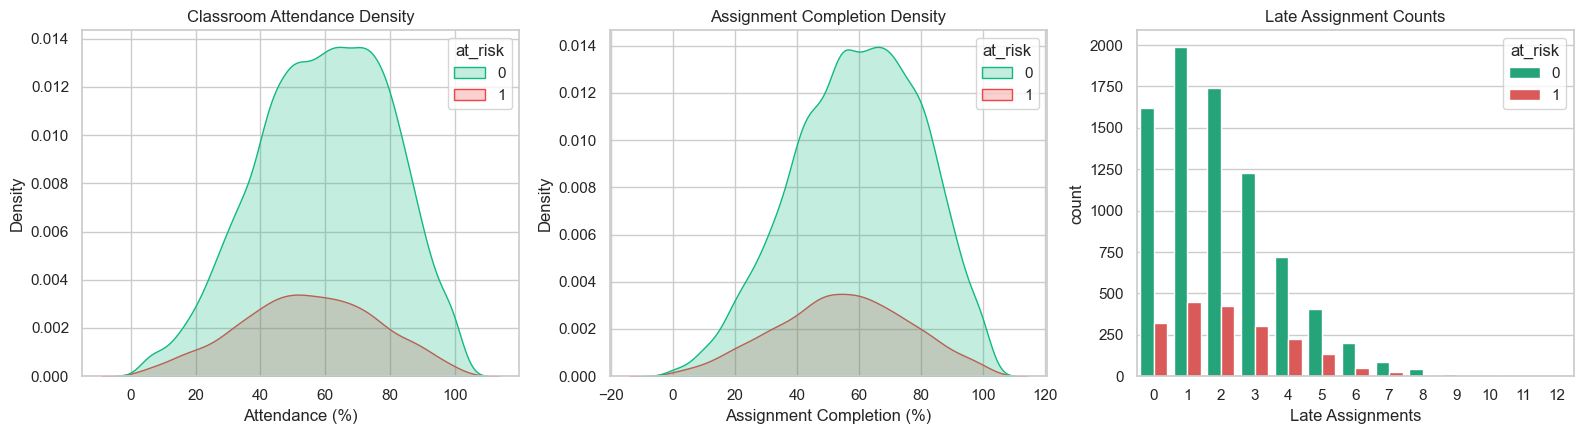

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.kdeplot(data=df, x="attendance_pct", hue=TARGET_COLUMN, palette={0: "#10B981", 1: "#EF4444"}, fill=True, ax=axes[0])
axes[0].set_title("Classroom Attendance Density")
axes[0].set_xlabel("Attendance (%)")

sns.kdeplot(data=df, x="assignment_completion_pct", hue=TARGET_COLUMN, palette={0: "#10B981", 1: "#EF4444"}, fill=True, ax=axes[1])
axes[1].set_title("Assignment Completion Density")
axes[1].set_xlabel("Assignment Completion (%)")

sns.countplot(data=df, x="late_assignment_count", hue=TARGET_COLUMN, palette={0: "#10B981", 1: "#EF4444"}, ax=axes[2])
axes[2].set_title("Late Assignment Counts")
axes[2].set_xlabel("Late Assignments")

plt.tight_layout()
plt.show()

## 5. Longitudinal Period Trends & Missing Value Diagnostics
We examine assessment period progression (Periods 1–4) and verify realistic MCAR/MAR missingness rates handled cleanly by median imputation inside the scikit-learn pipeline.

,assessment_period,at_risk,mean,std,count
0,1,0,61.000503,13.577961,2027
1,1,1,35.309937,10.461260,473
2,2,0,60.483288,13.170857,1892
3,2,1,35.981776,11.275654,608
4,3,0,56.355032,13.950714,2021
5,3,1,31.522109,10.647313,479
6,4,0,58.631519,14.114019,2106
7,4,1,32.699365,11.552804,394


,Missing (%)
assignment_completion_pct,2.01
attendance_pct,1.50
previous_score_2,0.35


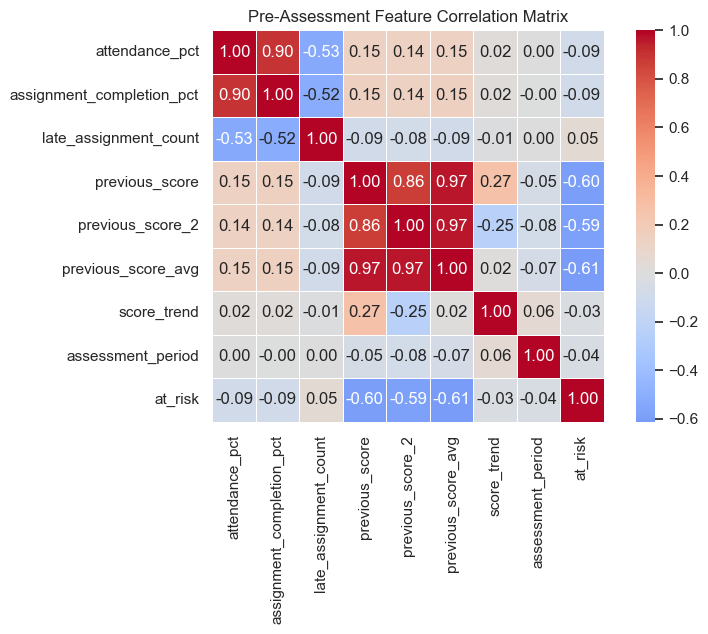

In [5]:
period_summary = df.groupby(["assessment_period", TARGET_COLUMN])["previous_score"].agg(["mean", "std", "count"]).reset_index()
display(period_summary)

missing_series = (df[FEATURE_COLUMNS].isna().mean() * 100).sort_values(ascending=False)
display(pd.DataFrame({"Missing (%)": missing_series[missing_series > 0].round(2)}))

corr_matrix = df[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Pre-Assessment Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 6. Candidate Model Benchmarks, Calibration & Error Analysis
We inspect the saved benchmark outputs produced by `src/train.py`, verifying validation-split sigmoid calibration, composite champion selection, and held-out Temporal & Student-Disjoint test performance.

In [6]:
with open(EVALUATION_METRICS_PATH, "r", encoding="utf-8") as f:
    eval_report = json.load(f)
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(f"Programmatic Champion Model: {metadata['model_name']} ({metadata['model_architecture']})")
print(f"Calibrated: {metadata['is_calibrated']} ({metadata['calibration_method']}) | Selected Threshold tau*: {metadata['selected_threshold']}")
print("Candidate Selection Scores:", metadata["candidate_selection_scores"])

bench_rows = []
sel_scores = eval_report.get("candidate_selection_scores", {})
for name, entry in eval_report["model_benchmarks"].items():
    tv = entry["temporal_validation"]
    dv = entry["student_disjoint_validation"]
    bench_rows.append({
        "Model": name,
        "Composite": sel_scores.get(name, {}).get("composite_score"),
        "Temp_Val_AP": tv["average_precision"],
        "Temp_Val_F2": tv["f2_score"],
        "Temp_Val_Brier": tv["brier_score"],
        "Disjoint_Val_AP": dv["average_precision"],
        "Disjoint_Val_ROC": dv["roc_auc"],
        "Latency_ms": entry["inference_latency_ms"],
    })
display(pd.DataFrame(bench_rows))

test_summary = pd.DataFrame([
    {"Split": "Temporal Held-Out Test (Period 4)", **eval_report["temporal_test_evaluation"]},
    {"Split": "Student-Disjoint Held-Out Test", **eval_report["disjoint_test_evaluation"]},
])[["Split", "sample_size", "positive_rate", "average_precision", "roc_auc", "recall", "precision", "specificity", "f1_score", "f2_score", "brier_score"]]
display(test_summary)

Programmatic Champion Model: XGBoost (XGBClassifier)
Calibrated: True (sigmoid) | Selected Threshold tau*: 0.18
Candidate Selection Scores: {'LogisticRegression': {'mean_average_precision': 0.8439, 'mean_roc_auc': 0.9476, 'temporal_val_optimized_f2': 0.8183, 'mean_brier_score': 0.0696, 'composite_score': 0.8764}, 'RandomForestClassifier': {'mean_average_precision': 0.8474, 'mean_roc_auc': 0.9501, 'temporal_val_optimized_f2': 0.8141, 'mean_brier_score': 0.0743, 'composite_score': 0.8765}, 'XGBoost': {'mean_average_precision': 0.8557, 'mean_roc_auc': 0.9512, 'temporal_val_optimized_f2': 0.8201, 'mean_brier_score': 0.0701, 'composite_score': 0.8818}}


,Model,Composite,Temp_Val_AP,Temp_Val_F2,Temp_Val_Brier,Disjoint_Val_AP,Disjoint_Val_ROC,Latency_ms
0,DummyClassifier,NaN,0.1912,0.0000,0.1553,0.2154,0.5000,0.0040
1,LogisticRegression,0.8764,0.8420,0.7430,0.0653,0.8459,0.9452,0.0046
2,RandomForestClassifier,0.8765,0.8459,0.8040,0.0742,0.8489,0.9473,0.1078
3,XGBoost,0.8818,0.8515,0.7918,0.0676,0.8599,0.9486,0.0090


,Split,sample_size,positive_rate,average_precision,roc_auc,recall,precision,specificity,f1_score,f2_score,brier_score
0,Temporal Held-Out Test (Period 4),2500,0.1576,0.8064,0.9420,0.8985,0.5221,0.8462,0.6604,0.7853,0.0677
1,Student-Disjoint Held-Out Test,1500,0.2100,0.8384,0.9448,0.8286,0.6887,0.9004,0.7522,0.7962,0.0723


## 7. Threshold Optimization Trade-Off & Error Audit Summary
We plot Precision vs. Recall vs. F2 across decision thresholds on the validation selection fold, and inspect feature profiles of False Negatives vs. True Positives.

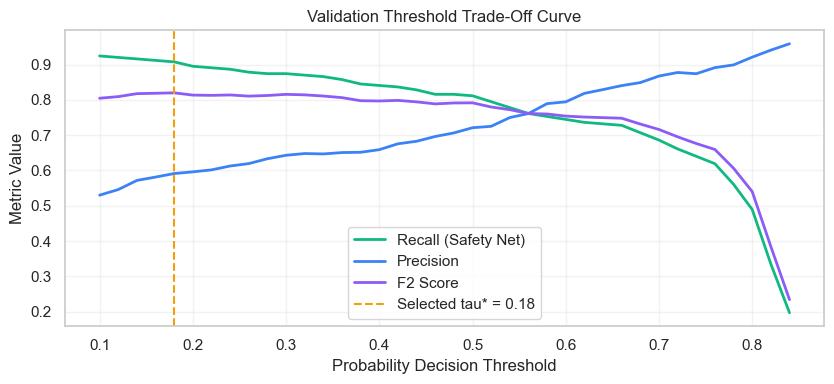

Temporal Test Calibration: Uncalibrated Brier=0.0959 (ECE=0.1172) -> Calibrated Brier=0.0677 (ECE=0.0427)


,False_Negatives,True_Positives,False_Positives,True_Negatives
count,40.00,354.00,324.00,1782.00
share_pct,1.60,14.16,12.96,71.28
mean_predicted_prob,0.06,0.74,0.51,0.03
mean_attendance_pct,53.84,54.64,55.20,59.85
mean_assignment_completion_pct,53.40,54.64,55.76,59.82
mean_late_assignment_count,2.75,2.33,2.23,2.03
mean_previous_score,51.72,30.55,39.87,62.04
mean_previous_score_2,49.69,28.26,36.49,59.02
mean_score_trend,2.03,2.29,3.38,3.02
mean_next_assessment_score,36.04,30.48,46.34,63.66


In [7]:
sweep_df = pd.DataFrame(eval_report["threshold_optimization_sweep"])
plt.figure(figsize=(8.5, 4))
plt.plot(sweep_df["threshold"], sweep_df["recall"], label="Recall (Safety Net)", linewidth=2, color="#10B981")
plt.plot(sweep_df["threshold"], sweep_df["precision"], label="Precision", linewidth=2, color="#3B82F6")
plt.plot(sweep_df["threshold"], sweep_df["f2_score"], label="F2 Score", linewidth=2, color="#8B5CF6")
plt.axvline(metadata["selected_threshold"], color="#F59E0B", linestyle="--", label=f"Selected tau* = {metadata['selected_threshold']}")
plt.title("Validation Threshold Trade-Off Curve")
plt.xlabel("Probability Decision Threshold")
plt.ylabel("Metric Value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

err = eval_report["temporal_test_error_analysis"]
cal = eval_report["calibration_analysis"]
print(
    f"Temporal Test Calibration: Uncalibrated Brier={cal['temporal_test_before']['brier_score']} (ECE={cal['temporal_test_before']['expected_calibration_error']}) -> "
    f"Calibrated Brier={cal['temporal_test_after']['brier_score']} (ECE={cal['temporal_test_after']['expected_calibration_error']})"
)
display(pd.DataFrame({
    "False_Negatives": err["false_negatives"],
    "True_Positives": err["true_positives"],
    "False_Positives": err["false_positives"],
    "True_Negatives": err["true_negatives"],
}).round(2))